# English to Arabic translation (Seq2Seq RNN, with and without attention)

In [1]:
import re
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(0)
random.seed(0)

I0000 00:00:1791814017.186806   29231 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791814017.224391   29231 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1791814020.191812   29231 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
df = pd.read_csv('Dataset.txt', sep='\t', header=None, names=['en', 'ar'], nrows=10000, quoting=3)
print(df.shape)
df.sample(5, random_state=0)

(10000, 2)


,en,ar
9394,"Which do you like better, meat or fish?",أيهما تفضل اللحم أم السمك؟
898,I'm from Tokyo.,أنا من طوكيو.
2398,The lights are out.,انطفأت الأضواء.
5906,He lost two sons in the war.,فقد ابنين في الحرب.
2343,My mother is angry.,والدتي غاضبة.


## Preprocessing
- english: lowercase, split punctuation from words
- arabic: remove diacritics and tatweel, split punctuation from words
- add `[start]` and `[end]` tokens to the arabic side (decoder input / target)

In [3]:
def clean_en(text):
    text = text.lower().replace('’', "'")
    text = re.sub(r"([?.!,])", r' \1 ', text)
    text = re.sub(r"[^a-z0-9'?.!, ]", ' ', text)
    return ' '.join(text.split())

def clean_ar(text):
    text = re.sub(r'[\u0617-\u061A\u064B-\u0652\u0670]', '', text)
    text = text.replace('ـ', '')
    text = re.sub(r'([؟?.!،,])', r' \1 ', text)
    return '[start] ' + ' '.join(text.split()) + ' [end]'

df['en_clean'] = df['en'].apply(clean_en)
df['ar_clean'] = df['ar'].apply(clean_ar)
df[['en_clean', 'ar_clean']].tail()

,en_clean,ar_clean
9995,this flower is more beautiful than that one .,[start] هذه الوردة أجمل من تلك . [end]
9996,this is just what tom didn't want to happen .,[start] هذا بالضبط ما لم يكن توم يريد حدوثه . ...
9997,this is the biggest cat that i've ever seen .,[start] هذه أكبر قطة رأيتها في حياتي . [end]
9998,today's paper says that a typhoon is coming .,[start] جريدة اليوم تحذر من قدوم عاصفة . [end]
9999,tom has called me many times this past week .,[start] اتصل بي توم مرات كثيرة الأسبوع الماضي ...


## Split 90/10 and tokenize
the file is sorted by sentence length, so the pairs are shuffled before splitting.

In [4]:
pairs = list(zip(df['en_clean'], df['ar_clean']))
random.shuffle(pairs)
n_val = len(pairs) // 10
train_pairs, val_pairs = pairs[n_val:], pairs[:n_val]

en_len = max(len(e.split()) for e, _ in pairs)
ar_len = max(len(a.split()) for _, a in pairs)
print(len(train_pairs), len(val_pairs), en_len, ar_len)

en_vec = layers.TextVectorization(standardize=None, output_sequence_length=en_len)
ar_vec = layers.TextVectorization(standardize=None, output_sequence_length=ar_len)
en_vec.adapt([e for e, _ in train_pairs])
ar_vec.adapt([a for _, a in train_pairs])
en_vocab, ar_vocab = en_vec.vocabulary_size(), ar_vec.vocabulary_size()
print(en_vocab, ar_vocab)

def make_data(pairs):
    src = en_vec([e for e, _ in pairs]).numpy()
    tgt = ar_vec([a for _, a in pairs]).numpy()
    # decoder input is the target shifted right, decoder output is the target shifted left
    return (src, tgt[:, :-1]), tgt[:, 1:]

X_train, y_train = make_data(train_pairs)
X_val, y_val = make_data(val_pairs)
X_train[0].shape, X_train[1].shape, y_train.shape

9000 1000 13 17


3497 8343


E0000 00:00:1791814022.032808   29231 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1791814022.033004   29296 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1791814022.050903   29231 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


((9000, 13), (9000, 16), (9000, 16))

## Models
both models use an embedding + LSTM encoder and an embedding + LSTM decoder trained with teacher forcing.
- **no attention**: the encoder only passes its final hidden/cell states to the decoder, so the whole sentence has to fit in one vector.
- **attention**: the encoder also returns all of its hidden states, and at every decoder step a Bahdanau (additive) attention layer builds a context vector from them. the context is concatenated with the decoder output before the output layers.

everything else (sizes, dropout, the dense tanh layer before the softmax) is the same in both models, so the only difference is the attention.
the data is small (9k pairs, ~8k arabic words) so both models overfit quickly, heavy dropout (0.5) helps.
training stops when the val accuracy stops improving and the best weights are kept.

padding is ignored in the loss and in the accuracy (token-level accuracy on non-padding tokens).

In [5]:
EMB, UNITS, DROP = 256, 512, 0.5

def masked_loss(y_true, y_pred):
    loss = tf.keras.losses.sparse_categorical_crossentropy(y_true, y_pred)
    mask = tf.cast(y_true != 0, loss.dtype)
    return tf.reduce_sum(loss * mask) / tf.reduce_sum(mask)

def masked_acc(y_true, y_pred):
    y_true = tf.cast(y_true, 'int64')
    match = tf.cast(tf.argmax(y_pred, -1) == y_true, 'float32')
    mask = tf.cast(y_true != 0, 'float32')
    return tf.reduce_sum(match * mask) / tf.reduce_sum(mask)

def build(attention):
    src = layers.Input((en_len,), name='src')
    tgt = layers.Input((ar_len - 1,), name='tgt_in')

    x = layers.Embedding(en_vocab, EMB, mask_zero=True)(src)
    x = layers.Dropout(DROP)(x)
    enc_out, h, c = layers.LSTM(UNITS, return_sequences=True, return_state=True)(x)

    # no mask here: padding is only at the end and is ignored by masked_loss / masked_acc
    y = layers.Embedding(ar_vocab, EMB)(tgt)
    y = layers.Dropout(DROP)(y)
    dec_out = layers.LSTM(UNITS, return_sequences=True)(y, initial_state=[h, c])

    if attention:
        context = layers.AdditiveAttention()([dec_out, enc_out])
        dec_out = layers.Concatenate()([dec_out, context])

    dec_out = layers.Dense(UNITS, activation='tanh')(dec_out)
    dec_out = layers.Dropout(DROP)(dec_out)
    out = layers.Dense(ar_vocab, activation='softmax')(dec_out)

    model = models.Model([src, tgt], out, name='attention' if attention else 'no_attention')
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss=masked_loss, metrics=[masked_acc])
    return model

setups = {'no_attention': build(False), 'attention': build(True)}
setups['attention'].summary()

Model: "attention"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ src (InputLayer)    │ (None, 13)        │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tgt_in (InputLayer) │ (None, 16)        │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_2         │ (None, 13, 256)   │    895,232 │ src[0][0]         │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_3         │ (None, 16, 256)   │  2,135,808 │ tgt_in[0][0]      │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 13, 256)   │          0 │ embedding_2[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_1         │ (None, 13)        │          0 │ src[0][0]         │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 16, 256)   │          0 │ embedding_3[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_2 (LSTM)       │ [(None, 13, 512), │  1,574,912 │ dropout_3[0][0],  │
│                     │ (None, 512),      │            │ not_equal_1[0][0] │
│                     │ (None, 512)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_3 (LSTM)       │ (None, 16, 512)   │  1,574,912 │ dropout_4[0][0],  │
│                     │                   │            │ lstm_2[0][1],     │
│                     │                   │            │ lstm_2[0][2]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ additive_attention  │ (None, 16, 512)   │        512 │ lstm_3[0][0],     │
│ (AdditiveAttention) │                   │            │ lstm_2[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 16, 1024)  │          0 │ lstm_3[0][0],     │
│ (Concatenate)       │                   │            │ additive_attenti… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 16, 512)   │    524,800 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 16, 512)   │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 16, 8343)  │  4,279,959 │ dropout_5[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 10,986,135 (41.91 MB)

 Trainable params: 10,986,135 (41.91 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
histories = {}
for name, model in setups.items():
    print(name)
    stop = tf.keras.callbacks.EarlyStopping(monitor='val_masked_acc', mode='max', patience=4, restore_best_weights=True)
    histories[name] = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                                epochs=30, batch_size=64, callbacks=[stop], verbose=2)

no_attention
Epoch 1/30


141/141 - 51s - 363ms/step - loss: 5.9307 - masked_acc: 0.2568 - val_loss: 5.3447 - val_masked_acc: 0.3054


Epoch 2/30


141/141 - 46s - 324ms/step - loss: 5.0893 - masked_acc: 0.3279 - val_loss: 5.1235 - val_masked_acc: 0.3407


Epoch 3/30


...

141/141 - 57s - 408ms/step - loss: 0.5391 - masked_acc: 0.8540 - val_loss: 5.0945 - val_masked_acc: 0.4895


Epoch 29/30


141/141 - 57s - 404ms/step - loss: 0.5075 - masked_acc: 0.8614 - val_loss: 5.1389 - val_masked_acc: 0.4912


Epoch 30/30


141/141 - 53s - 374ms/step - loss: 0.4820 - masked_acc: 0.8705 - val_loss: 5.1991 - val_masked_acc: 0.4935


## Loss curves

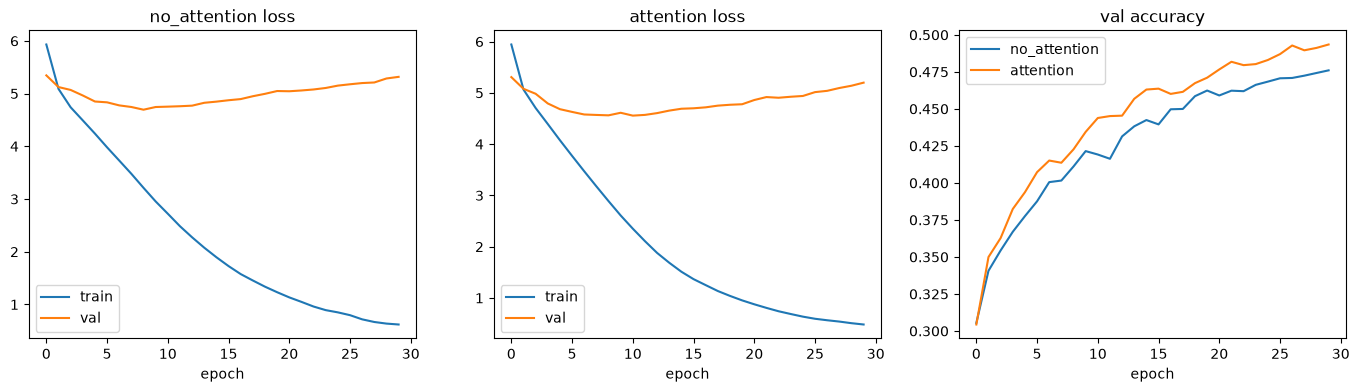

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, (name, h) in zip(axes, histories.items()):
    ax.plot(h.history['loss'], label='train')
    ax.plot(h.history['val_loss'], label='val')
    ax.set_title(name + ' loss')
    ax.set_xlabel('epoch')
    ax.legend()
for name, h in histories.items():
    axes[2].plot(h.history['val_masked_acc'], label=name)
axes[2].set_title('val accuracy')
axes[2].set_xlabel('epoch')
axes[2].legend()
plt.show()

## Results on the val set

In [8]:
scores = {name: model.evaluate(X_val, y_val, verbose=0) for name, model in setups.items()}
pd.DataFrame(scores, index=['val_loss', 'val_acc']).T

,val_loss,val_acc
no_attention,5.313407,0.476060
attention,5.196887,0.494486


## Translating
greedy decoding: start with `[start]`, predict the next word, append it, and repeat until `[end]`.

In [9]:
ar_words = np.array(ar_vec.get_vocabulary())
start_id = ar_vec.get_vocabulary().index('[start]')
end_id = ar_vec.get_vocabulary().index('[end]')

def translate(model, sentences):
    src = en_vec([clean_en(s) for s in sentences])
    tgt = np.zeros((len(sentences), ar_len - 1), dtype='int64')
    tgt[:, 0] = start_id
    for i in range(ar_len - 2):
        probs = model.predict([src, tgt], verbose=0)
        tgt[:, i + 1] = probs[:, i].argmax(-1)
    results = []
    for row in tgt[:, 1:]:
        words = []
        for t in row:
            if t == end_id or t == 0:
                break
            words.append(ar_words[t])
        results.append(' '.join(words))
    return results

In [10]:
samples = val_pairs[:10]
src = [e for e, _ in samples]
preds = {name: translate(model, src) for name, model in setups.items()}
for i, (e, a) in enumerate(samples):
    print('en          :', e)
    print('true        :', a.replace('[start] ', '').replace(' [end]', ''))
    print('no attention:', preds['no_attention'][i])
    print('attention   :', preds['attention'][i])
    print()

en          : tom isn't strict enough with his students .
true        : توم ليس صارما بما فيه الكفاية مع طلابه .
no attention: توم ليس متسامحا مثلي .
attention   : توم ليس مثلي ولا اشهر .

en          : it tastes really good .
true        : إنها لذيذة .
no attention: إنها لذيذة حادة .
attention   : إنها لذيذة المذاق .

en          : let's sing the song in english .
true        : لنغني بالإنجليزية .
no attention: لنغني هذه الأغنية بالإنجليزية .
attention   : لنغني هذه الأغنية بالإنجليزية .

en          : what's that ?
true        : ما ذلك ؟
no attention: ما هذا ؟
attention   : ما هذا ؟

en          : norway is the richest country in the world .
true        : النرويج هي أغنى دولة في العالم .
no attention: الحديقة الواقف على التلة قديم .
attention   : كلاهما في الطابق الرابع .

en          : the car crashed into the truck .
true        : إصطدمت السيارة بالشاحنة .
no attention: تعطلت السيارة فعليهم .
attention   : اصطدمت السيارة إلى الوقود .

en          : i want to be able to read french 

## New sentences

In [11]:
sentences = [
    'I love my little sister.',
    'Where is the train station?',
    'Tom is reading a new book.',
    'We will go to school tomorrow.',
    'This house is very old.',
    'My father works in a hospital.',
]
print(any(clean_en(s) in set(df['en_clean']) for s in sentences))  # make sure none are in the dataset

preds = {name: translate(model, sentences) for name, model in setups.items()}
for i, s in enumerate(sentences):
    print(s)
    print('  no attention:', preds['no_attention'][i])
    print('  attention   :', preds['attention'][i])

False


I love my little sister.
  no attention: أحب الشعر القصير .
  attention   : أنا أحب أن أكون وحدي .
Where is the train station?
  no attention: أين غرفة محطة ميلادك ؟
  attention   : أين المحطة العام القادم ؟
Tom is reading a new book.
  no attention: توم يقرأ كتابا
  attention   : توم يقرأ كتابا
We will go to school tomorrow.
  no attention: ذهبنا إلى أمريكا في الغد .
  attention   : ذهبنا إلى المدرسة غدا .
This house is very old.
  no attention: هذا البيت صغير جدا .
  attention   : هذا البيت كبير جدا .
My father works in a hospital.
  no attention: يعيش أبي في مصنع .
  attention   : يعمل أبي في طوكيو .
